# ۱۱ - تحلیل‌های ترکیبی

اجرای کامل هر شش تحلیل ترکیبی صورت‌مسئله، از جمله سه تحلیل الزامی.

## ۲. سؤال‌های کسب‌وکاری

1. کدام دسته‌بندی‌های پرفروش رضایت پایین دارند؟
2. کدام ایالت‌ها هم کند هستند و هم پرتأخیر؟
3. آیا قیمت بالاتر با امتیاز بالاتر همراه است؟
4. آیا مبلغ پرداخت بالا با اقساط بیشتر همراه است؟
5. کدام دسته‌بندی‌ها در طول زمان رشد کرده‌اند؟
6. کدام فروشندگان با حجم بالا امتیاز پایین دارند؟

## ۱. عنوان و هدف

اجرای کامل هر شش تحلیل ترکیبی صورت‌مسئله، از جمله سه تحلیل الزامی.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

هر شش تحلیل ترکیبی با اتصال چند جدول انجام می‌شود. در همه موارد گرین (grain) صریح است و محاسبه امتیاز روی سفارش‌های یکتا انجام می‌شود.

## ۶. تحلیل عددی

### تحلیل ۱ - دسته‌بندی‌های پرفروش با رضایت پایین

In [2]:
table, flagged = M.combined_revenue_vs_satisfaction(ds)
print("دسته‌بندی‌های نیازمند بررسی:", len(flagged))
display(flagged)

دسته‌بندی‌های نیازمند بررسی: 8


,category_label,revenue,pct_revenue,n_reviews,mean_score,score_vs_overall
0,watches_gifts,1205005.68,8.8658,5576,4.07,-0.03
1,bed_bath_table,1036988.68,7.6296,9313,3.97,-0.13
2,computers_accessories,911954.32,6.7097,6649,4.03,-0.07
3,furniture_decor,729762.49,5.3692,6398,4.01,-0.09
4,auto,592720.11,4.3609,3877,4.09,-0.01
5,baby,411764.89,3.0295,2861,4.04,-0.06
6,telephony,323667.53,2.3814,4168,4.00,-0.09
7,office_furniture,273960.70,2.0157,1263,3.62,-0.48


In [3]:
display(table.nlargest(12, "revenue"))

,category_label,revenue,pct_revenue,n_reviews,mean_score,score_vs_overall,is_high_revenue,below_average_score
0,health_beauty,1258681.34,9.2607,8771,4.18,0.08,True,False
1,watches_gifts,1205005.68,8.8658,5576,4.07,-0.03,True,True
2,bed_bath_table,1036988.68,7.6296,9313,3.97,-0.13,True,True
3,sports_leisure,988048.97,7.2695,7669,4.17,0.07,True,False
4,computers_accessories,911954.32,6.7097,6649,4.03,-0.07,True,True
5,furniture_decor,729762.49,5.3692,6398,4.01,-0.09,True,True
6,cool_stuff,635290.85,4.6741,3599,4.17,0.07,True,False
7,housewares,632248.66,4.6517,5843,4.14,0.04,True,False
8,auto,592720.11,4.3609,3877,4.09,-0.01,True,True
9,garden_tools,485256.46,3.5703,3496,4.14,0.04,True,False


### تحلیل ۲ - موقعیت جغرافیایی و عملکرد تحویل

In [4]:
states, eligible, thresholds = M.combined_geography_delivery(ds)
display(pd.Series(thresholds, name="value"))
display(eligible)

slow_threshold_days    18.2550
late_threshold_pct      9.6524
Name: value, dtype: float64

,customer_state,n_orders,mean_delivery_days,median_delivery_days,mean_promised_days,n_late,mean_early_days,pct_late,meets_min_sample,rank_slowest,is_slow,is_late_prone,needs_attention
0,AL,397,24.54,22.33,32.58,85,-8.71,21.4106,True,4,True,True,True
1,PA,946,23.77,21.08,37.16,106,-14.07,11.2051,True,5,True,True,True
2,MA,717,21.57,19.19,30.46,125,-9.57,17.4338,True,6,True,True,True
3,SE,335,21.52,18.01,30.85,51,-10.02,15.2239,True,7,True,True,True
4,CE,1279,21.27,18.21,31.38,176,-10.8,13.7608,True,8,True,True,True
5,PB,517,20.43,18.15,33.03,54,-13.26,10.4449,True,10,True,True,True
6,PI,476,19.46,16.29,30.09,66,-11.31,13.8655,True,11,True,True,True
7,BA,3256,19.34,16.91,29.43,396,-10.79,12.1622,True,13,True,True,True
8,AM,145,26.43,25.88,45.28,4,-19.57,2.7586,True,3,True,False,False
9,RO,243,19.37,17.58,38.77,7,-20.1,2.8807,True,12,True,False,False


### تحلیل ۳ - قیمت محصول و رضایت مشتری

In [5]:
deciles, price_stats = M.combined_price_vs_satisfaction(ds)
display(pd.Series(price_stats, name="value"))
display(deciles[["price_band", "n_orders", "median_price", "mean_score", "pct_1_or_2"]])

n_orders                       97917
spearman_rho                 -0.0029
mean_score_lowest_decile      4.1108
mean_score_highest_decile     4.0581
score_range_across_deciles    0.1059
currency                         BRL
Name: value, dtype: object

,price_band,n_orders,median_price,mean_score,pct_1_or_2
0,1-25,10298,18.9,4.11,13.7502
1,25-35,9365,29.9,4.14,13.1127
2,35-49,9976,42.1,4.12,13.7831
3,49-60,10074,55.0,4.13,13.6490
4,60-79,9465,69.9,4.07,14.7174
5,79-99,9771,89.9,4.07,14.9319
6,99-122,9593,109.9,4.16,12.6446
7,122-159,9791,139.9,4.08,14.7789
8,159-240,9824,189.9,4.11,14.4340
9,"240-6,735",9760,369.0,4.06,16.0758


### تحلیل ۴ - مبلغ پرداخت و تعداد اقساط

In [6]:
bins, payment_stats = M.combined_payment_vs_installments(ds)
display(pd.Series(payment_stats, name="value"))
display(bins[["value_band", "n_transactions", "mean_installments", "pct_multi_installment"]])

n_transactions                          103884.0000
n_orders_with_payment                    99440.0000
spearman_rho_transaction_level               0.4111
spearman_rho_credit_card_only                0.4776
spearman_rho_order_level                     0.3817
mean_installments_lowest_decile              1.2092
mean_installments_highest_decile             5.3260
pct_multi_installment_lowest_decile         15.0556
pct_multi_installment_highest_decile        73.4983
Name: value, dtype: float64

,value_band,n_transactions,mean_installments,pct_multi_installment
0,0-35,10428,1.21,15.0556
1,35-49,10362,1.65,30.9593
2,49-64,10376,1.95,36.3820
3,64-80,10388,2.25,42.9342
4,80-100,10555,2.55,45.3340
5,100-123,10222,2.97,56.6914
6,123-154,10389,3.08,59.1010
7,154-196,10390,3.50,65.8133
8,196-297,10386,4.05,68.6694
9,"297-13,664",10388,5.33,73.4983


### تحلیل ۵ - تغییرات فروش دسته‌بندی‌ها در طول زمان

In [7]:
pivot, trend = M.combined_category_revenue_over_time(ds)
display(trend)

,category_label,total_revenue,mean_monthly_revenue_first_half,mean_monthly_revenue_second_half,pct_change_second_vs_first_half,coefficient_of_variation,peak_month,peak_month_share_pct,months_used,is_sustained_growth,is_spike_driven
0,health_beauty,1253993.86,34137.07,91262.32,167.3409,0.5263,2018-08,9.6335,20,True,False
1,watches_gifts,1201645.44,32334.23,87830.31,171.6326,0.5505,2018-05,10.3086,20,True,False
2,bed_bath_table,1036509.69,35852.20,67798.76,89.1063,0.4318,2017-11,8.6263,20,True,False
3,sports_leisure,984715.33,32748.21,65723.32,100.6928,0.4418,2018-01,9.2996,20,True,False
4,computers_accessories,910555.00,29454.20,61601.30,109.1426,0.5390,2018-02,11.0762,20,True,False


### تحلیل ۶ - عملکرد فروشندگان و رضایت مشتری

In [8]:
candidates, threshold = M.high_revenue_low_rating_sellers(ds)
display(candidates[["seller_id", "n_items", "revenue", "n_reviews", "mean_score", "score_vs_overall"]])

,seller_id,n_items,revenue,n_reviews,mean_score,score_vs_overall
0,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,976,3.49,-0.60
1,2eb70248d66e0e3ef83659f71b244378,212,42628.61,198,2.70,-1.39
2,712e6ed8aa4aa1fa65dab41fed5737e4,87,39815.00,78,3.38,-0.70
3,88460e8ebdecbfecb5f9601833981930,302,31546.55,247,3.41,-0.67
4,710e3548e02bc1d2831dfc4f1b5b14d4,142,23979.11,135,3.36,-0.72
5,8444e55c1f13cd5c179851e5ca5ebd00,109,22873.21,99,3.26,-0.82
6,8e6d7754bc7e0f22c96d255ebda59eba,130,14497.27,85,3.58,-0.51
7,0b35c634521043bf4b47e21547b99ab5,78,13533.65,50,3.36,-0.73
8,1ca7077d890b907f89be8c954a02686a,137,13341.57,114,2.33,-1.75
9,c60b801f2d52c7f7f91de00870882a75,41,12913.50,41,3.32,-0.77


### شرکت‌کنندگان در هر تحلیل ترکیبی

In [9]:
rows = [
    ("تحلیل ۱ - دسته‌بندی پرفروش با رضایت پایین", "Member B + Member C"),
    ("تحلیل ۲ - جغرافیا و تحویل", "Member B + Member C"),
    ("تحلیل ۳ - قیمت و رضایت", "Member B"),
    ("تحلیل ۴ - مبلغ پرداخت و اقساط", "Member B"),
    ("تحلیل ۵ - فروش دسته‌بندی در زمان", "Member A + Member C"),
    ("تحلیل ۶ - فروشنده و رضایت", "Member C"),
]
display(pd.DataFrame(rows, columns=["تحلیل", "مسئول اصلی"]))

,تحلیل,مسئول اصلی
0,تحلیل ۱ - دسته‌بندی پرفروش با رضایت پایین,Member B + Member C
1,تحلیل ۲ - جغرافیا و تحویل,Member B + Member C
2,تحلیل ۳ - قیمت و رضایت,Member B
3,تحلیل ۴ - مبلغ پرداخت و اقساط,Member B
4,تحلیل ۵ - فروش دسته‌بندی در زمان,Member A + Member C
5,تحلیل ۶ - فروشنده و رضایت,Member C


## ۷. نمودارها

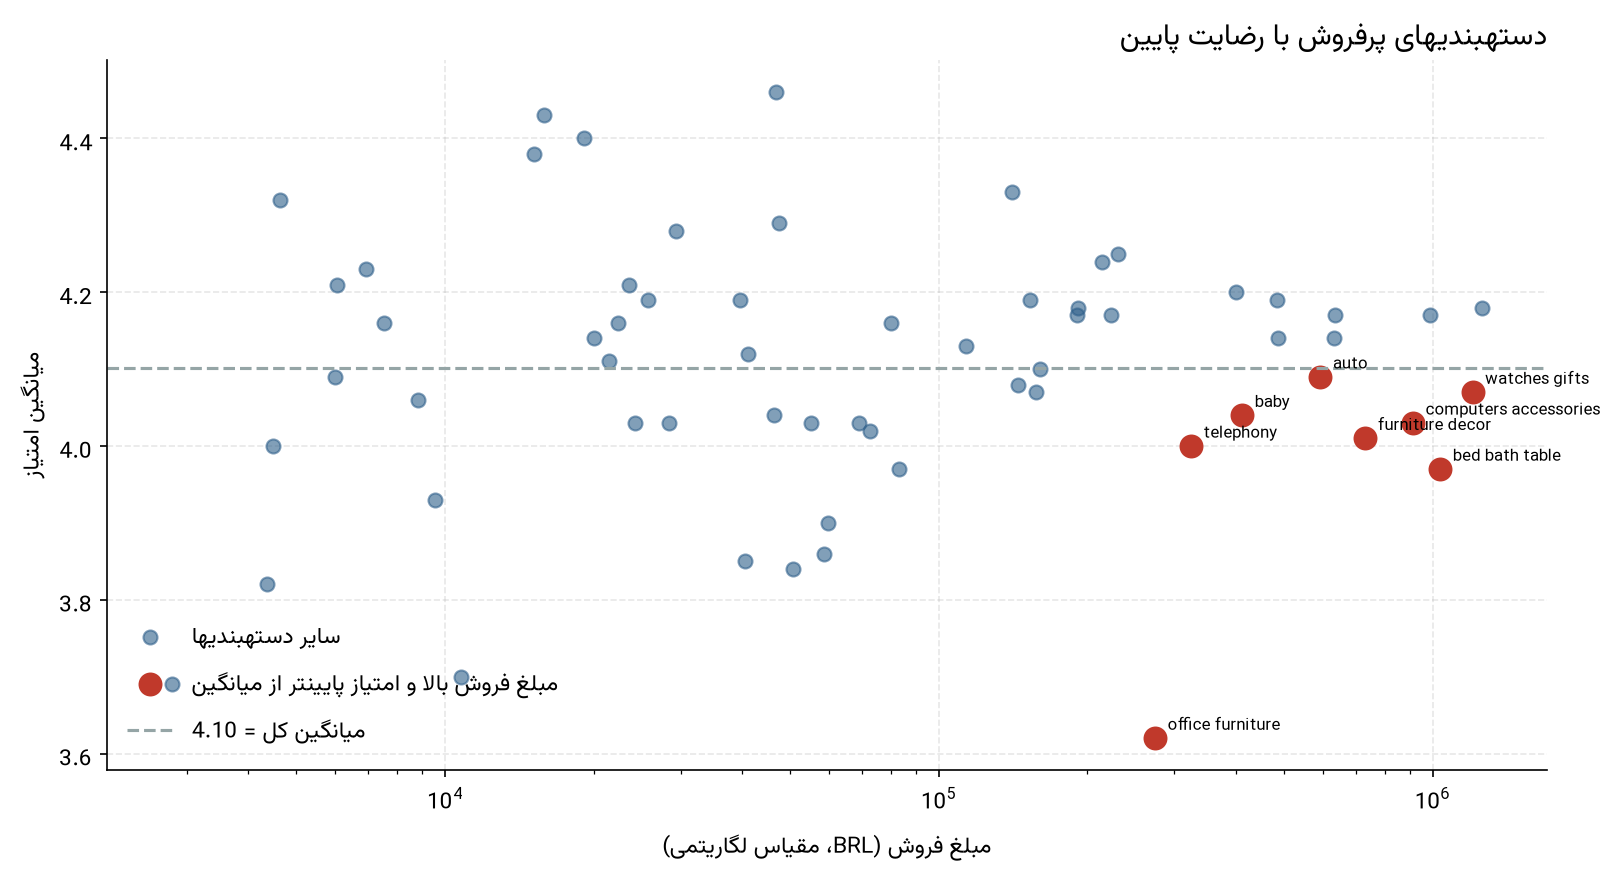

نمودار ۲۶ - تحلیل ترکیبی اول: دستهبندیهای نیازمند بررسی


In [10]:
display(Image(filename=str(FIGURES_DIR / "fig_26_combined_revenue_vs_score.png"), width=920))
caption = FIGURES_DIR / "fig_26_combined_revenue_vs_score.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

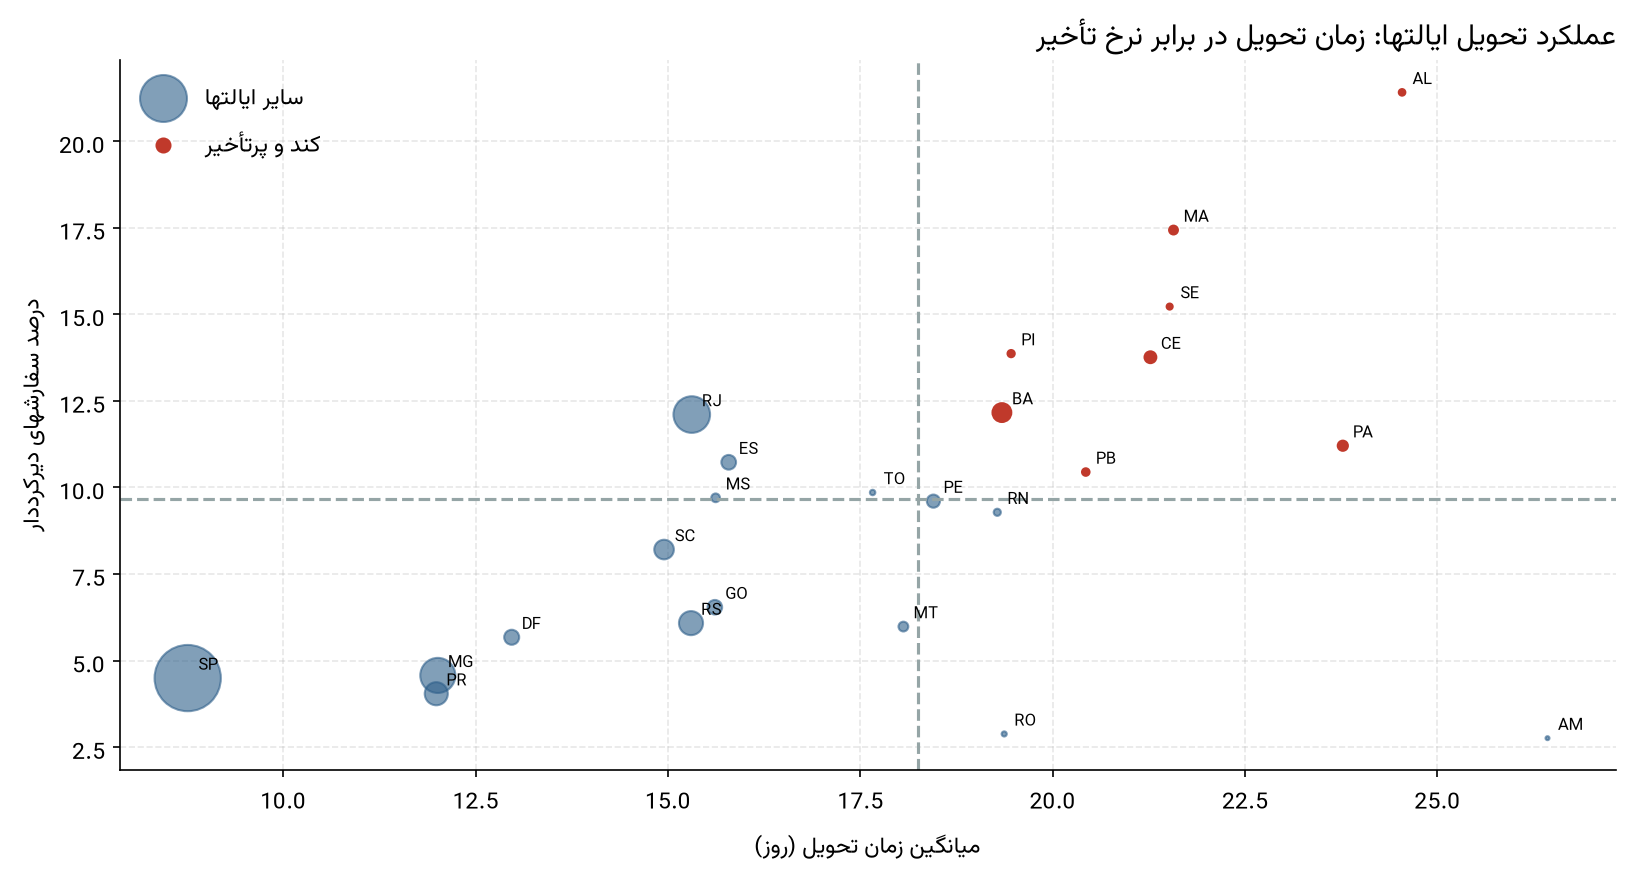

نمودار ۲۷ - تحلیل ترکیبی دوم؛ اندازه نقطه نشاندهنده تعداد سفارش است


In [11]:
display(Image(filename=str(FIGURES_DIR / "fig_27_combined_geography_delivery.png"), width=920))
caption = FIGURES_DIR / "fig_27_combined_geography_delivery.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

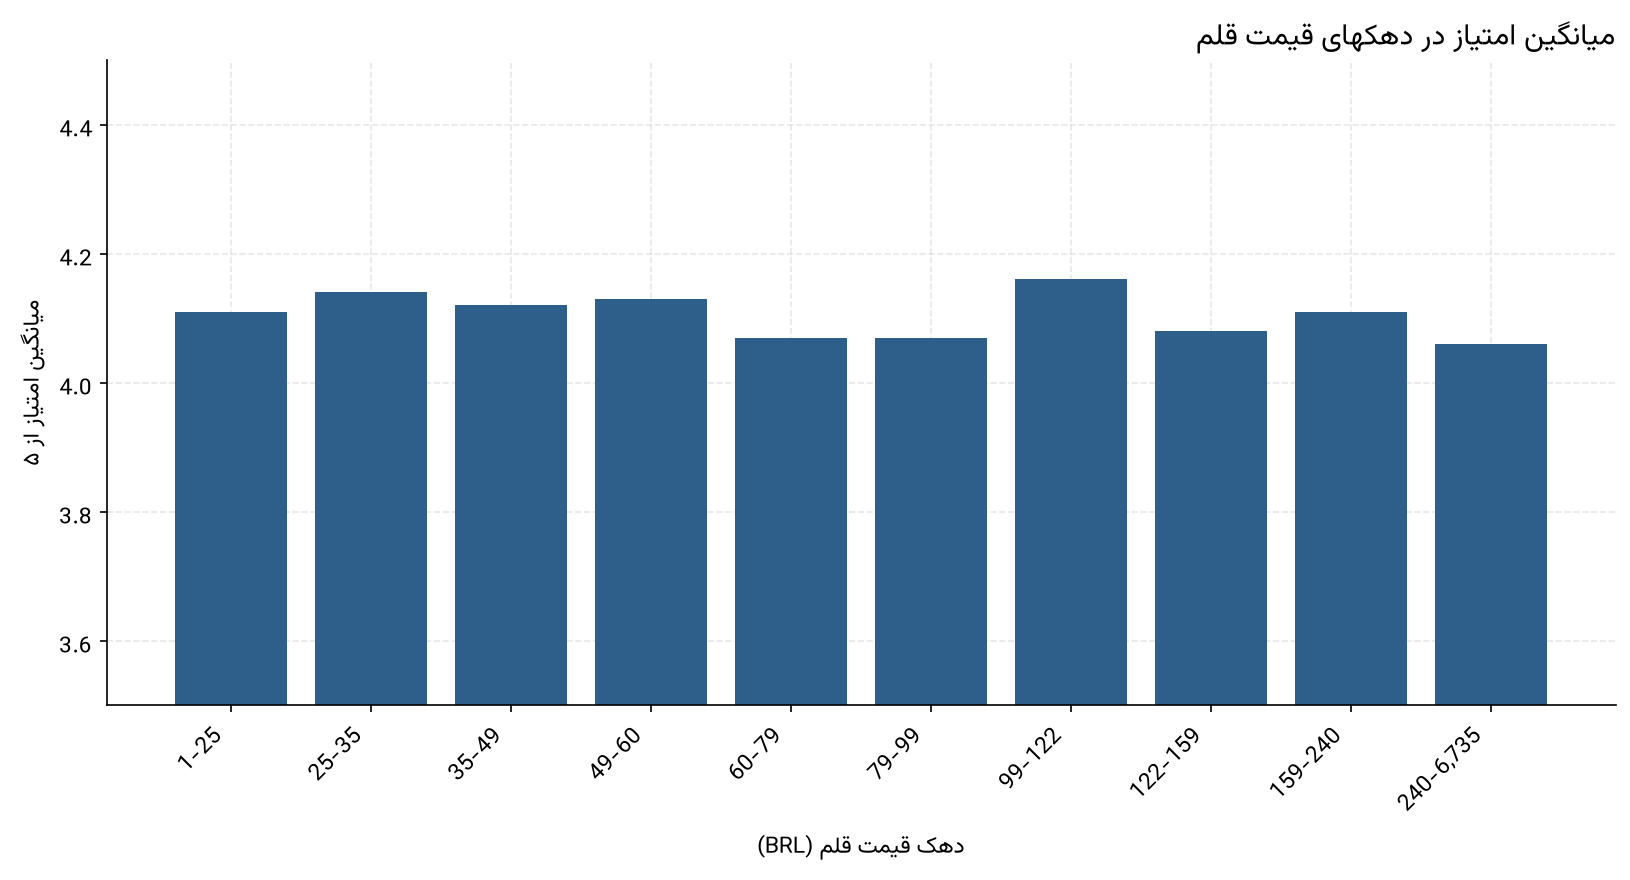

نمودار ۲۸ - تحلیل ترکیبی سوم: رابطه قیمت و رضایت عملاً وجود ندارد


In [12]:
display(Image(filename=str(FIGURES_DIR / "fig_28_combined_price_vs_score.png"), width=920))
caption = FIGURES_DIR / "fig_28_combined_price_vs_score.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

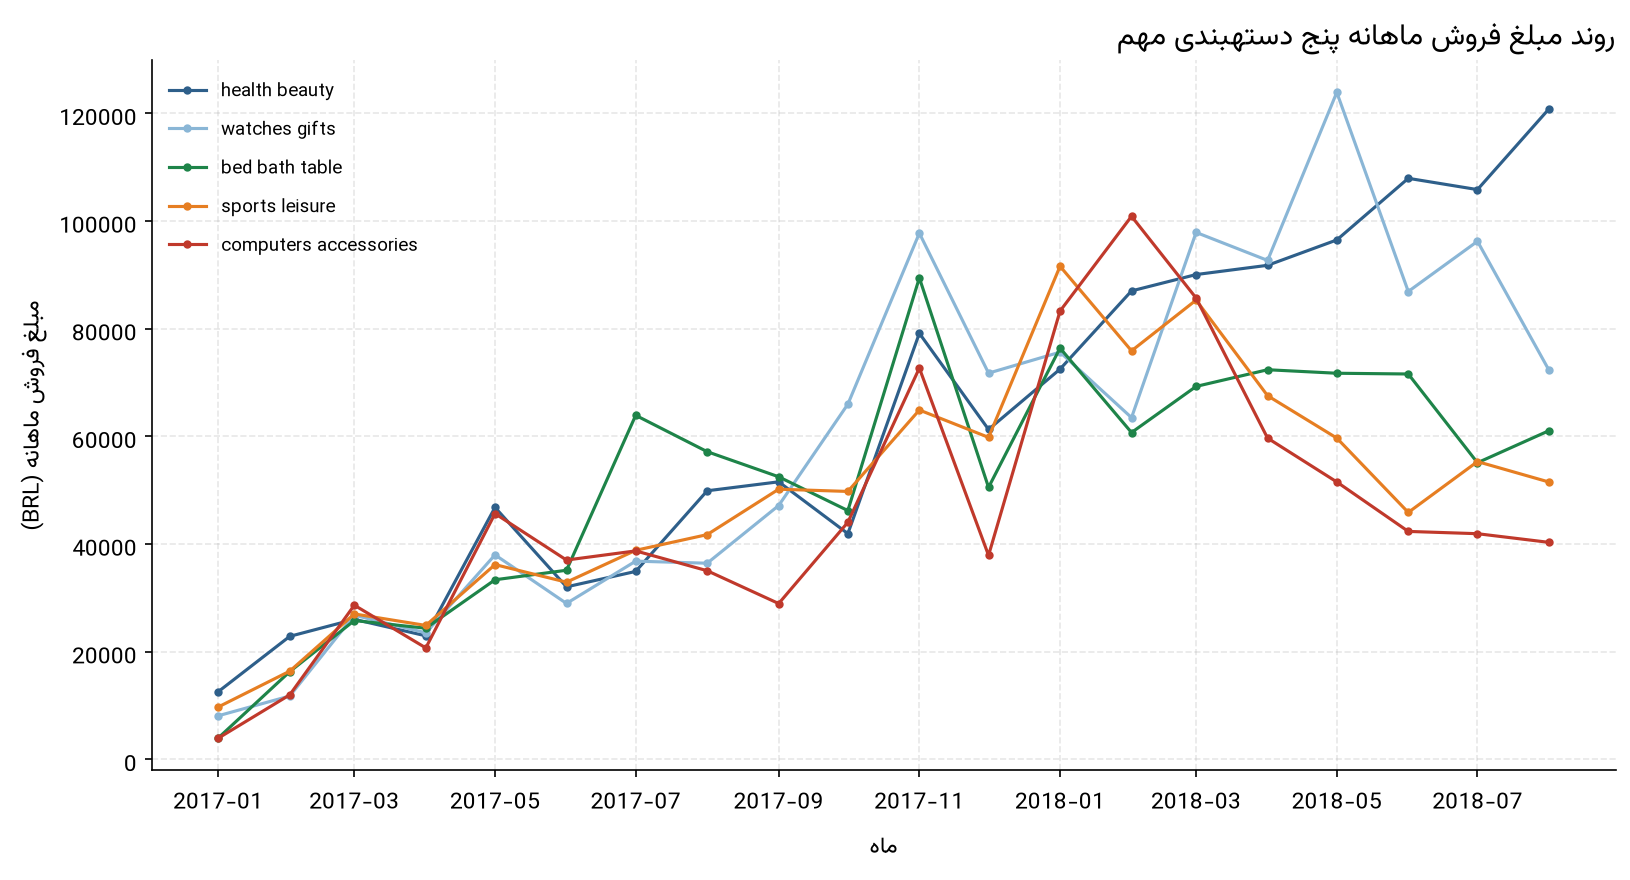

نمودار ۲۹ - تحلیل ترکیبی پنجم: رشد دستهبندیهای اصلی در طول زمان


In [13]:
display(Image(filename=str(FIGURES_DIR / "fig_29_combined_category_revenue_trend.png"), width=920))
caption = FIGURES_DIR / "fig_29_combined_category_revenue_trend.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

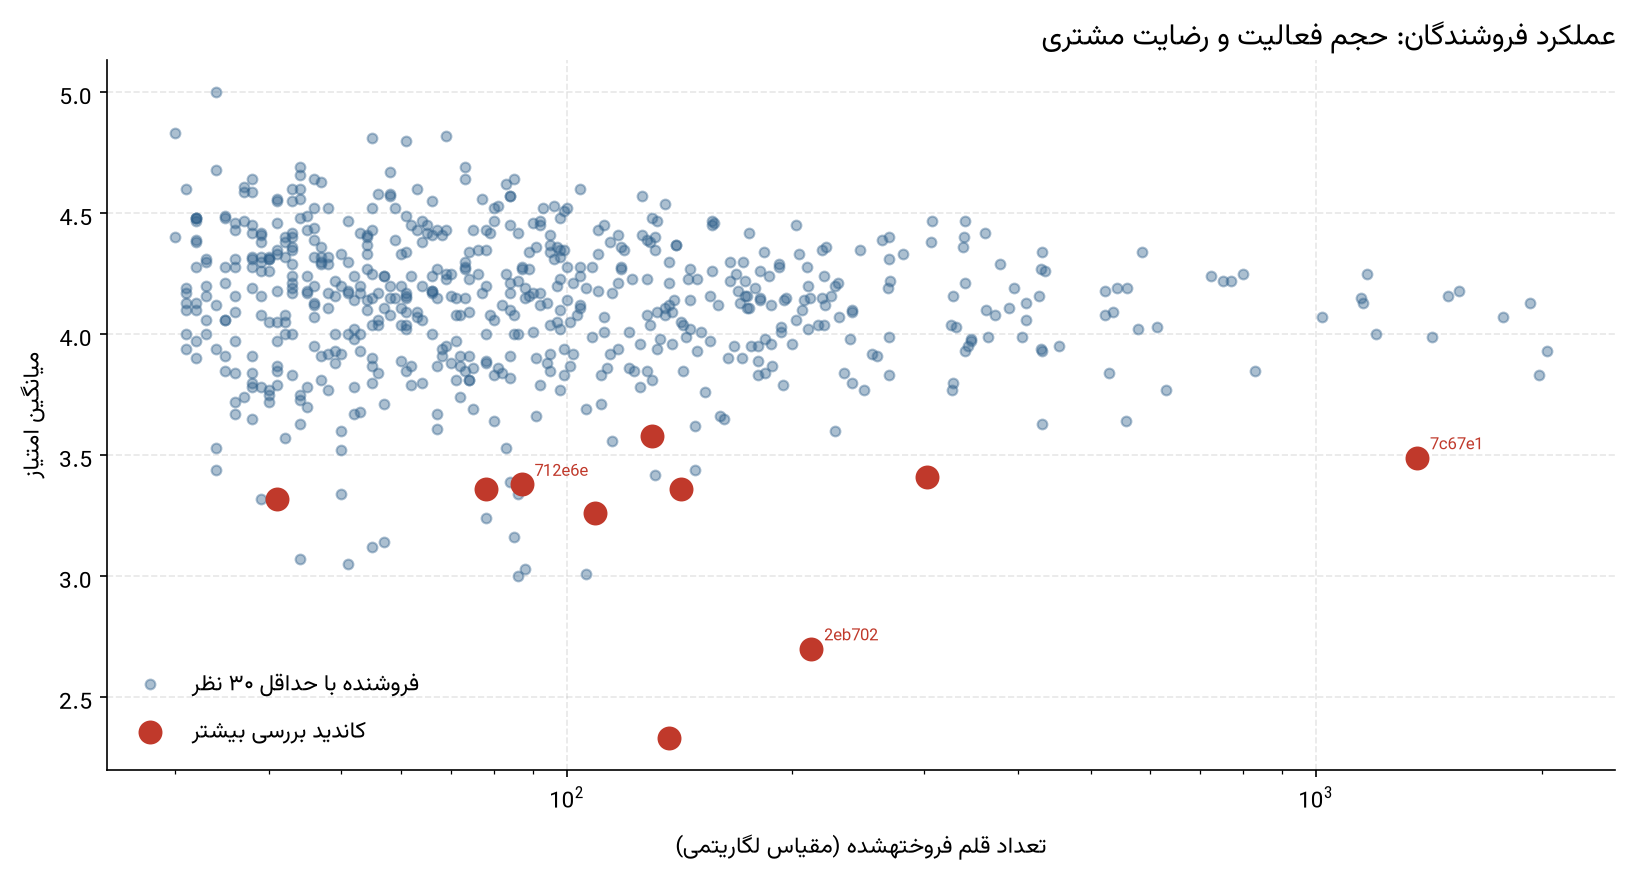

نمودار ۳۰ - تحلیل ترکیبی ششم: فروشندگان با حجم بالا و امتیاز پایین


In [14]:
display(Image(filename=str(FIGURES_DIR / "fig_30_combined_seller_satisfaction.png"), width=920))
caption = FIGURES_DIR / "fig_30_combined_seller_satisfaction.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- ۸ دسته‌بندی هم‌زمان در چارک بالای مبلغ فروش و زیر میانگین امتیاز قرار دارند؛ `office_furniture` با ۲۷۳٬۹۶۱ رئال و امتیاز ۳.۶۲ شاخص‌ترین است.
- ۸ ایالت هم‌زمان کند و پرتأخیر هستند و از این میان AL با ۲۱.۴۱ درصد نرخ تأخیر و ۲۴.۵۴ روز میانگین تحویل بدترین است.
- رابطه قیمت و امتیاز عملاً وجود ندارد: ضریب اسپیرمن منفی ۰.۰۰۳ و اختلاف میانگین امتیاز کم‌قیمت‌ترین و گران‌ترین دهک تنها ۰.۰۵ امتیاز است.
- رابطه مبلغ پرداخت و اقساط مثبت و قابل توجه است: از ۱.۲۱ قسط در کم‌مبلغ‌ترین دهک تا ۵.۳۳ قسط در پرمبلغ‌ترین دهک.
- هر پنج دسته‌بندی اصلی در نیمه دوم پنجره تحویل رشد داشته‌اند (`health_beauty` ۱۶۷.۳۴ درصد) و رشد آن‌ها پایدار بوده، نه تک‌ماهه.
- سه فروشنده برای بررسی بیشتر معرفی می‌شوند: `7c67e144…`، `2eb70248…` و `712e6ed8…`.

## ۹. تفسیر کسب‌وکاری

تحلیل‌های ترکیبی تصویر عملیاتی روشنی می‌سازند: مشکل اصلی نه قیمت‌گذاری است و نه تقاضا، بلکه کیفیت تجربه تحویل و کیفیت کالا در چند دسته‌بندی پرحجم. اهرم‌های تجاری مانند اقساط نیز رفتار منطقی و قابل پیش‌بینی دارند.

## ۱۰. محدودیت‌های تحلیل

آستانه‌های «پرفروش» و «امتیاز پایین» نسبی و بر پایه چارک‌ها و میانگین همین داده تعریف شده‌اند؛ با داده به‌روز ممکن است فهرست پرچم‌خورده‌ها تغییر کند. همه روابط، همبستگی توصیفی‌اند.

## ۱۱. نتیجه‌گیری

هر شش تحلیل ترکیبی اجرا شد و هر سه تحلیل الزامی دوره در آن‌ها پوشش داده شده است. خروجی این نوتبوک، پایه بخش یافته‌ها و پیشنهادهای گزارش مدیریتی است.